In [1]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [2]:
# The uncertainty factors, or dnb nodes
factortuples = [
    ("HHA", 3, ()),  # 0
    ("GER", 2, ()),  # 1
    ("OMA", 2, ()),  # 2

    ("PIS0", 5, ()), # 3
    ("PIH0", 5, (0,3,)), # 4
    ("LYS0", 4, (3,4,)), # 5
    ("LYH0", 7, (0,3,4,5,)), # 6
    ("AST0", 3, (1,2,4,6,)), # 7

    ("PISt", 5, (3,4,5,6,)), # 8
    ("PIHt", 5, (1,2,4,6,8,)), # 9
    ("LYSt", 4, (1,2,5,6,8,9,)), # 10
    ("LYHt", 7, (1,2,6,8,9,10,)), # 11
    ("ASTt", 3, (9,11,)), # 12
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]

In [3]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784, 0])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])

In [4]:
cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        cross_impacts[(parent_index, fi)] = np.ones((parent_dim, factor_dim))

In [6]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

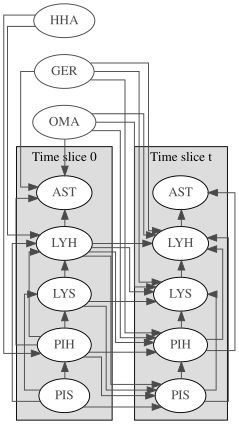

In [16]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

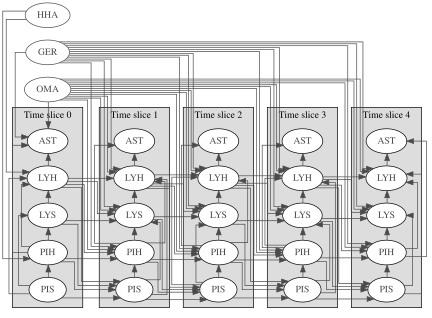

In [19]:
T = 5
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [9]:
dbn.cpt("LYS4")

(pyagrum.Tensor@0x2ef494f0) 
                                         ||  LYS4                                 |
GER   |OMA   |LYS3  |LYH3  |PIS4  |PIH4  ||0        |1        |2        |3        |
------|------|------|------|------|------||---------|---------|---------|---------|
0     |0     |0     |0     |0     |0     || 0.9592  | 0.0111  | 0.0204  | 0.0093  |
1     |0     |0     |0     |0     |0     || 0.9628  | 0.0104  | 0.0188  | 0.0079  |
0     |1     |0     |0     |0     |0     || 0.9592  | 0.0111  | 0.0204  | 0.0093  |
1     |1     |0     |0     |0     |0     || 0.9628  | 0.0104  | 0.0188  | 0.0079  |
0     |0     |1     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
1     |0     |1     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
[...2788 more line(s) ...]
0     |1     |2     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |2     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |0     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |0     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |1     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |